# Joint vs R2D2M2 vs stated scales on real designs, refitted by lme4

**Contents**
1. Motivation
2. Load real designs
3. Results: Ranks
4. Results: Coverage and Similarity
5. Results: Singular, saturated and failed refits
6. Results: The slope over d
7. Conclusion

References


## 1. Motivation

The [previous experiment on simulated datasets](simulated.ipynb) compared prior structures for generalized linear mixed models (GLMMs).<br>
Only the `tabdgp` joint prior kept the marginal R² and saturation in the link functions independent of the design size.<br>
However, the comparison was based on ground truth parameters and simulated covariates.

### 1.1 Setup
This experiment draws y on the designs of real tables, refits them $k$ times with the same settings, and checks how similar the original and semi-synthetic fits are.<br>
We reuse the main idea of simulation-based calibration (Talts et al., 2020):<br>
if a generative prior is close enough to the unknown underlying prior, each real fit's rank should be uniform among the refits.<br>
A real fit's rank can be between $0$ (below every refit) and $k$ (above every refit).<br>
Under uniformity, $2 / (k + 1)$ of the fits fall outside the range, so to keep this error level at 5%, we use $k = 39$.

The rank histogram interpretation (by shape):
- **∩:** the prior is wider than real tables.
- **U:** the prior is narrower than real tables (on both sides).
- **Falling:** the prior's levels are too high.
- **Rising:** the prior's levels are too low.

### 1.2 Measures
We compare the real fits and the refits using the measures below, defined as in the [previous experiment](simulated.ipynb) (Nakagawa et al., 2017).
- **$R^2_m$, $R^2_c$ and the fixed share $R^2_m / R^2_c$:** the marginal and the conditional R² per fit.
- **Intraclass correlation (ICC):** one per grouping factor.
- **sd(η):** the standard deviation of the fitted linear predictor (logit and log links only).
- **Singular share:** the share of fits that lme4 flags as singular.
- **Saturated share:** the share of fits with some $|\hat\eta| > 10$ (logit and log links only).
- **Failed share:** the share of draws whose refit fails under lme4.

Note: For fits without slopes (design matrix rank $d = 1$), $R^2_m$ and the fixed share are 0 and dropped for the comparison.


## 2. Load real designs

- **Registry:** `mixedbench` (1.0.13) - real grouped tables from public sources with documented lme4 fits.
- **Excluded:** we excluded the 17 slowest fits whose refits would have taken most of the compute time.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from mixedbench import registry

from tabdgp import fidelity

SEED = 2026  # the ties' random draws
ESTIMATED = ['ok', 'singular', 'warning']  # the statuses of a fit with estimates
FAMILIES = ['gaussian', 'bernoulli', 'poisson']
LINKS = ['bernoulli', 'poisson']  # the families whose link saturates
BINS = 10  # the rank histograms' bins, 4 of the 40 ranks each
# each prior's arm in registry.csv.gz: the joint prior at TabDGP's defaults
# (joint-phi-tau0-logit on the logit link, whose τ differs), the rivals at its intercept
ARMS = {
    'joint': 'joint-phi-tau0',
    'r2d2m2': 'r2d2m2-0.5-tau0',
    'survey': 'survey-tau0',
    'unit': 'unit-tau0',
}
LOGIT_ARM = 'joint-phi-tau0-logit'


def selectPriors(records: pd.DataFrame) -> pd.DataFrame:
    # each prior's records under its name, on the fits the joint prior ran on
    parts = []
    for prior, arm in ARMS.items():
        selected = records['arm'] == arm
        if prior == 'joint':
            logit = records['family'] == 'bernoulli'
            selected = (selected & ~logit) | ((records['arm'] == LOGIT_ARM) & logit)
        parts.append(records[selected].assign(prior=prior))
    selected = pd.concat(parts).drop(columns='arm')
    ran = selected[selected['prior'] == 'joint']['task'].unique()
    return selected[selected['task'].isin(ran)]


fits = pd.read_csv('registry-fits.csv')  # a row per registry model, its task or why it was dropped
records = pd.read_csv('registry.csv.gz')  # a row per fit, draw and arm
tasks = fits[fits['task'].notna()].astype({'task': int, 'rank': int, 'factors': int})
records = selectPriors(records.merge(tasks[['task', 'family', 'rank']], on='task'))
tasks = tasks[tasks['task'].isin(records['task'])]
print(f'{len(tasks)} of {len(fits)} registry models, {len(records)} draws')
print(tasks['family'].value_counts()[FAMILIES].to_string())

761 of 931 registry models, 121167 draws
family
gaussian     536
bernoulli    132
poisson       93


In [2]:
MEASURES = {
    'r2_marginal': 'marginal R²',
    'r2_conditional': 'conditional R²',
    'fixed_share': 'fixed share',
    'icc': 'ICC',
    'sd_eta': 'sd(η)',
}
PER_FIT = ['r2_marginal', 'r2_conditional', 'fixed_share', 'sd_eta']  # one value per fit


def selectMeasures(table: pd.DataFrame) -> pd.DataFrame:
    # sd(η) only on the logit and log links, R²_m and the fixed share only on fits with slopes
    table = table.merge(tasks[['task', 'family', 'rank']], on='task')
    raw_scale = (table['family'] == 'gaussian') & (table['measure'] == 'sd_eta')
    no_slopes = (table['rank'] == 1) & table['measure'].isin(['r2_marginal', 'fixed_share'])
    return table[~raw_scale & ~no_slopes]


def readFits() -> pd.DataFrame:
    # fits.csv holds a row per grouping factor, the fit's own measures repeated on each
    fits_table = pd.read_csv(registry.path('fits.csv'), keep_default_na=False, na_values=[''])
    model_index = fits_table['model_index'].astype(str)
    fits_table['id'] = fits_table['source'] + '/' + fits_table['object'] + '/' + model_index
    return fits_table.merge(tasks[['id', 'task']], on='id')


def readRegistry(fits_table: pd.DataFrame) -> pd.DataFrame:
    # the fit's own measures, the fixed share at the records' 4 decimals
    per_fit = fits_table.drop_duplicates('task').copy()
    explained = per_fit['sigma2_fixed'] + per_fit['sigma2_random']
    per_fit['fixed_share'] = (per_fit['sigma2_fixed'] / explained).round(4)
    measures = per_fit.melt(id_vars='task', value_vars=PER_FIT, var_name='measure')
    measures['factor'] = 0

    # each factor's ICC, numbered in lme4's order, the order of a fit's rows and its refits' columns
    factors = fits_table[['task', 'icc']].rename(columns={'icc': 'value'})
    factors['factor'] = factors.groupby('task').cumcount() + 1
    factors['measure'] = 'icc'
    return selectMeasures(pd.concat([measures, factors]).dropna(subset=['value']))


def readRefits() -> pd.DataFrame:
    # each refit's measures, a row per measure and factor
    fitted = records[records['fit_status'].isin(ESTIMATED)]
    parts = []
    for measure in PER_FIT:
        part = fitted[['task', 'draw', 'prior']].assign(
            measure=measure, factor=0, value=fitted[f'fit_{measure}']
        )
        parts.append(part)
    for factor in range(1, tasks['factors'].max() + 1):
        part = fitted[['task', 'draw', 'prior']].assign(
            measure='icc', factor=factor, value=fitted[f'fit_icc_{factor}']
        )
        parts.append(part)
    return selectMeasures(pd.concat(parts).dropna(subset=['value']))


fits_table = readFits()  # fits.csv's rows of the kept fits, a row per fit and factor
real = readRegistry(fits_table)  # a row per fit, measure and factor (factor 0 for the fit's own)
refits = readRefits()  # a row per refit, measure and factor

## 3. Results: Ranks

In [3]:
def rankRegistry(rng: np.random.Generator) -> pd.DataFrame:
    # each real fit's estimate against the refits of its fit and factor under each prior
    paired = refits.merge(
        real[['task', 'measure', 'factor', 'value']],
        on=['task', 'measure', 'factor'],
        suffixes=('', '_registry'),
    )
    paired['below'] = paired['value'] < paired['value_registry']
    paired['tied'] = paired['value'] == paired['value_registry']
    ranks = paired.groupby(['family', 'measure', 'task', 'factor', 'prior'], as_index=False).agg(
        below=('below', 'sum'), tied=('tied', 'sum'), refits=('value', 'size')
    )

    # the histogram's bin: ties (an ICC of 0 on a singular fit) broken at random,
    # the rank spread into BINS bins by (r + V) / (m + 1) with V uniform, for any m
    rank = ranks['below'] + rng.integers(0, ranks['tied'] + 1)
    spread = (rank + rng.random(len(ranks))) / (ranks['refits'] + 1)
    ranks['bin'] = np.floor(BINS * spread).astype(int)

    # the chance that the random tie-break puts the rank at 0 or at m
    at_bottom = (ranks['below'] == 0) / (ranks['tied'] + 1)
    at_top = (ranks['below'] + ranks['tied'] == ranks['refits']) / (ranks['tied'] + 1)
    ranks['outside'] = at_bottom + at_top
    ranks['expected'] = 2 / (ranks['refits'] + 1)  # the share outside if the ranks are uniform
    return ranks


ranks = rankRegistry(np.random.default_rng(SEED))

In [4]:
# three hues (joint, R2D2M2, stated), a dashed line for the stated priors' second
PRIOR_STYLES = {
    'joint': {'color': '#2a78d6', 'linestyle': '-'},
    'r2d2m2': {'color': '#eb6834', 'linestyle': '-'},
    'survey': {'color': '#1baf7a', 'linestyle': '-'},
    'unit': {'color': '#1baf7a', 'linestyle': '--'},
}


def plotRanks(family: str) -> None:
    # one family's distributions and ranks per measure, saved as registry-<family>.pdf
    measures = []
    for measure in MEASURES:
        if (real[real['family'] == family]['measure'] == measure).any():
            measures.append(measure)
    figure, axes = plt.subplots(
        len(measures),
        1 + len(ARMS),
        figsize=(2.125 * (1 + len(ARMS)), 2.1 * len(measures)),
        squeeze=False,
        layout='constrained',
    )
    for row, measure in enumerate(measures):
        ax = axes[row, 0]
        in_registry = real[(real['family'] == family) & (real['measure'] == measure)]
        ax.ecdf(in_registry['value'], color='black', linewidth=2.5, label='registry')
        under_priors = refits[(refits['family'] == family) & (refits['measure'] == measure)]
        for prior in ARMS:
            under_prior = under_priors[under_priors['prior'] == prior]
            ax.ecdf(under_prior['value'], **PRIOR_STYLES[prior], label=prior)
        if measure == 'sd_eta':
            # the priors' extremes would squeeze the real fits' range of an sd
            ax.set_xscale('log')
            ax.set_xlim(in_registry['value'].min() / 10, in_registry['value'].max() * 10)
        ax.set_ylabel(MEASURES[measure])
        ax.grid(color='#e4e3df', linewidth=0.6)
        ax.spines[['top', 'right']].set_visible(False)

        # each prior's ranks, on one y scale per row
        ranked = ranks[(ranks['family'] == family) & (ranks['measure'] == measure)]
        shares = {}
        for prior in ARMS:
            bins = ranked[ranked['prior'] == prior]['bin']
            shares[prior] = np.bincount(bins, minlength=BINS) / len(bins)
        top = 1.05 * max(share.max() for share in shares.values())
        for column, prior in enumerate(ARMS, start=1):
            ax = axes[row, column]
            ax.bar(range(BINS), shares[prior], width=0.85, color=PRIOR_STYLES[prior]['color'])
            ax.axhline(1 / BINS, color='black', linestyle='--', linewidth=1)
            ax.set_ylim(0, top)
            ax.set_xticks([0, BINS - 1], ['0-3', '36-39'])
            ax.spines[['top', 'right']].set_visible(False)
            if row == 0:
                ax.set_title(prior)
            if row == len(measures) - 1:
                ax.set_xlabel("registry's rank")
    axes[0, 0].set_title('distribution')
    axes[-1, 0].set_xlabel('value')
    handles, labels = axes[0, 0].get_legend_handles_labels()
    figure.legend(handles, labels, loc='outside lower center', ncol=len(labels), frameon=False)
    figure.suptitle(f'{family} y')
    figure.savefig(f'registry-{family}.pdf', metadata={'CreationDate': None})

### Figures
The first panel compares the empirical cumulative distribution functions (ECDFs) of the real fits and the refits per prior structure.<br>
The other panels show the real fits' rank histogram under each prior structure (dashed: uniform share).

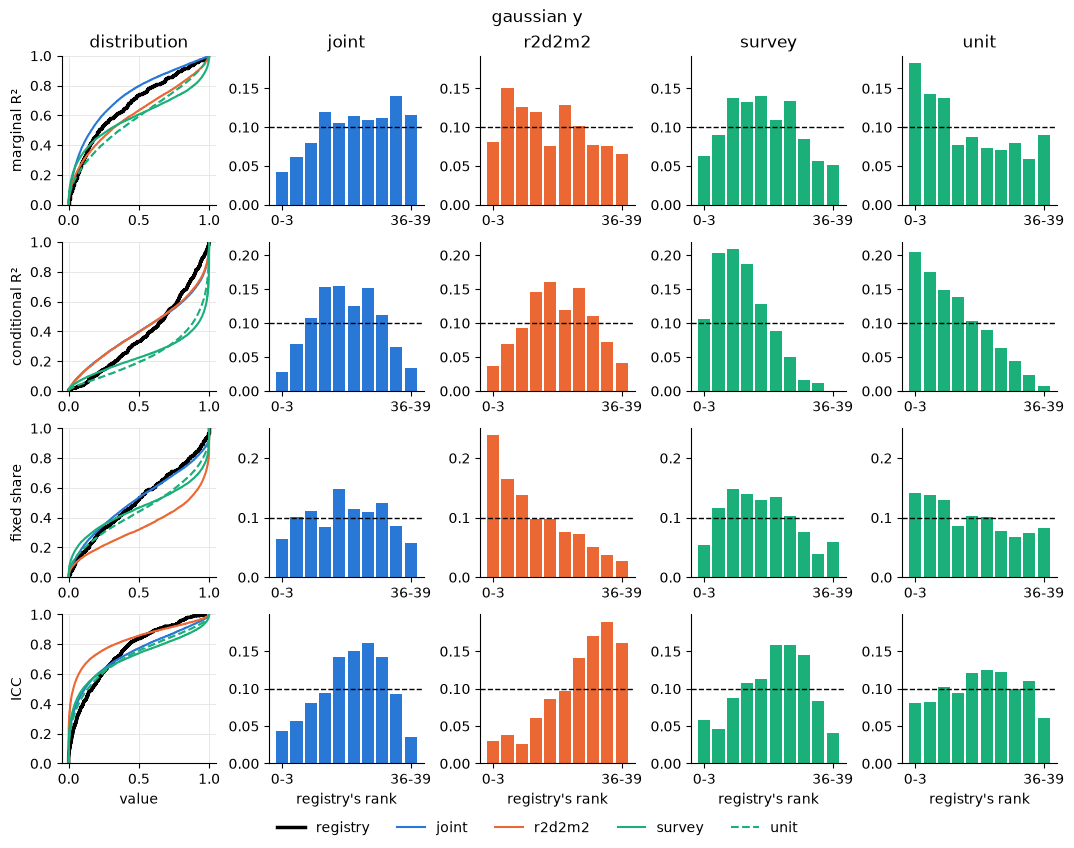

In [5]:
plotRanks('gaussian')

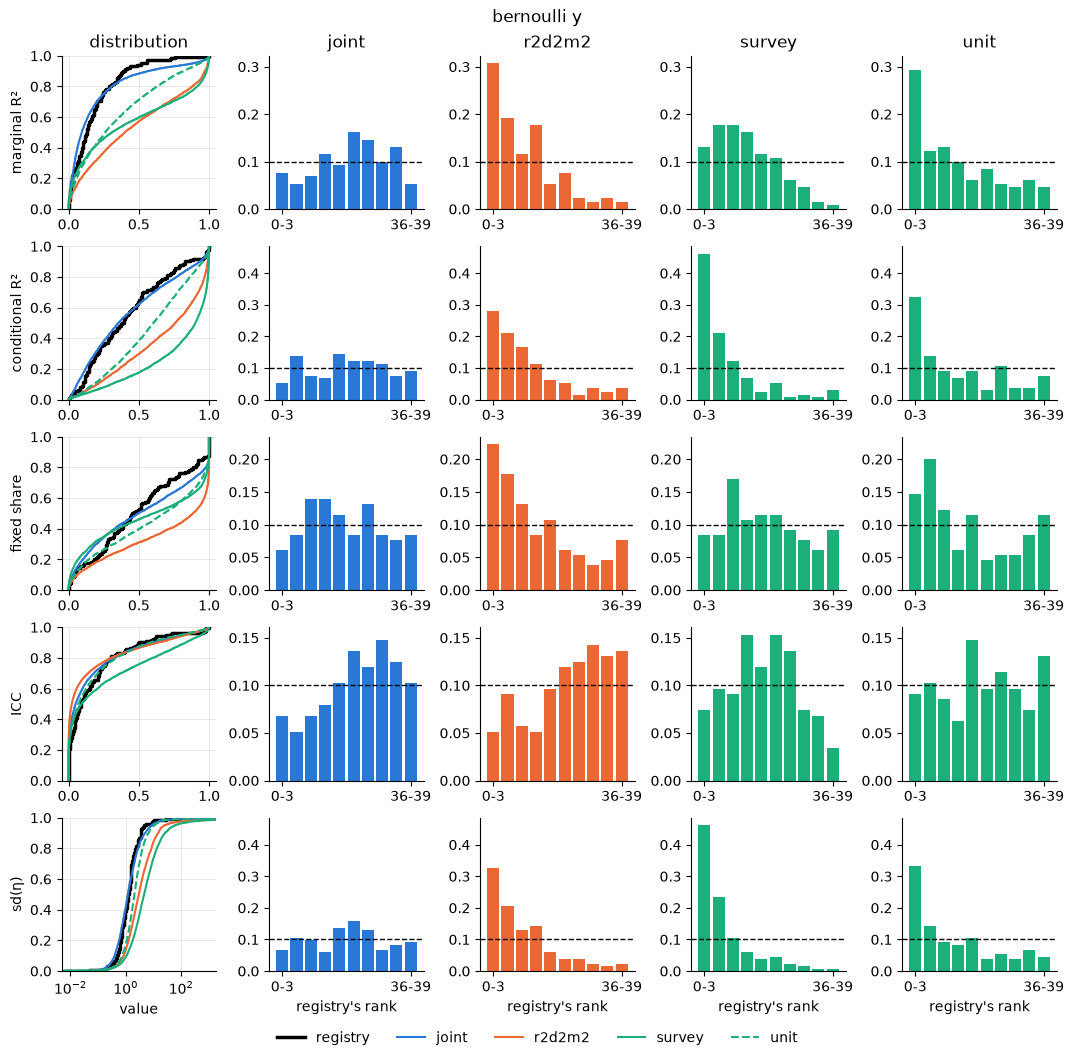

In [6]:
plotRanks('bernoulli')

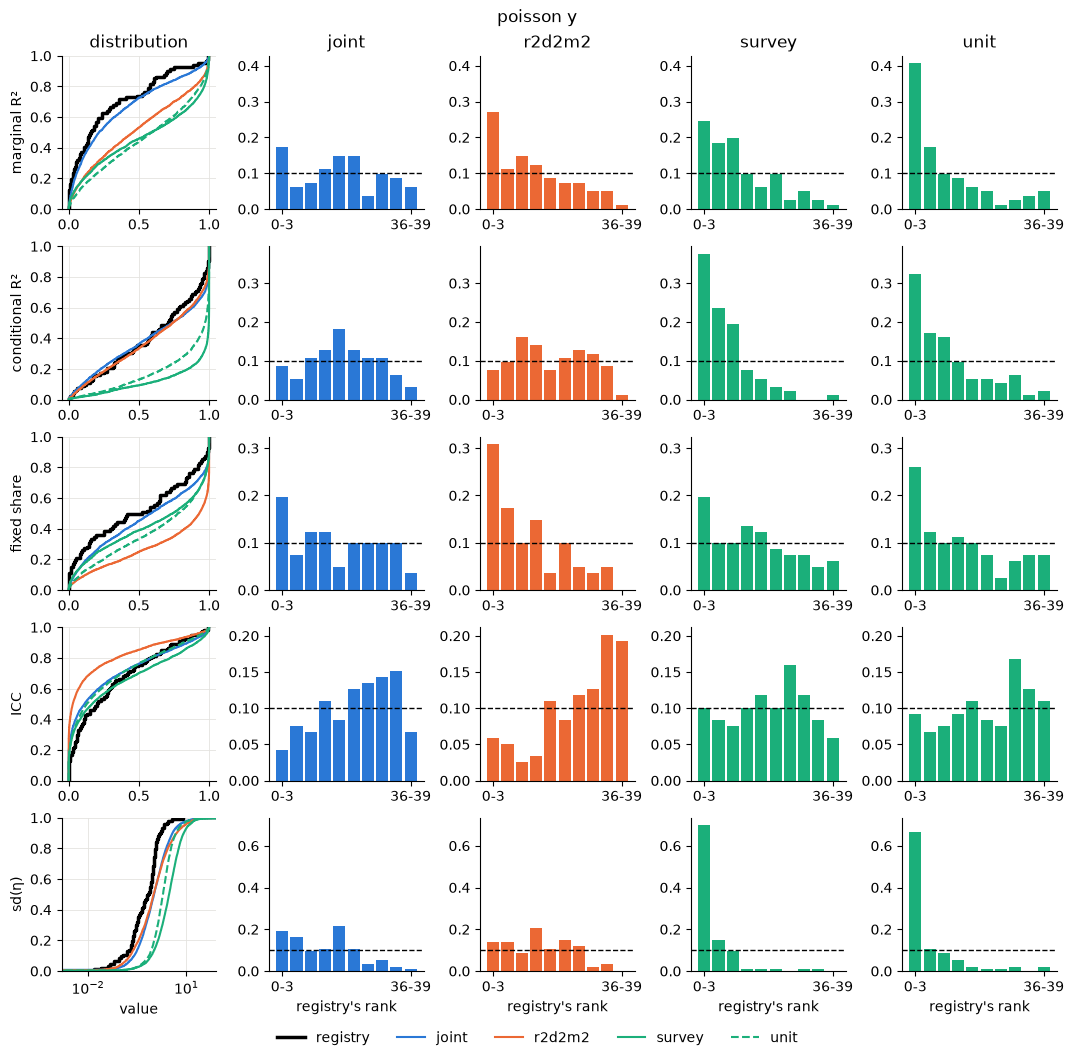

In [7]:
plotRanks('poisson')

Under the joint prior, the histograms are flat or ∩-shaped on Gaussian and Bernoulli fits, and falling on the $R^2_m$, fixed share and sd(η) of Poisson fits.<br>
R2D2M2's histograms fall on the fixed share and rise on the ICC in every family, as its Dirichlet gives the fixed effects their share of the terms.<br>
They also fall on the $R^2_m$, $R^2_c$ and sd(η) of Bernoulli fits.<br>
The stated scales' histograms fall on $R^2_c$ in every family and on sd(η) of Bernoulli and Poisson fits.

## 4. Results: Coverage and Similarity

For each family, measure and prior, we report:
- **outside:** the share of real fits outside the range of their refits (marked + or - where it is significantly above or below).
- **distance:** the Wasserstein-1 (W1) distance between the real fits and the refits on their pooled ranks, from 0 to 1.

Uniform ranks leave 5% outside in expectation. We test against the joint prior with the 95% interval of the paired difference.

In [8]:
def estimateInterval(difference: pd.Series) -> tuple[float, float]:
    # the mean's 95 % interval by the normal approximation, clustered by fit
    residuals = (difference - difference.mean()).groupby(level='task').sum()  # (b,)
    clusters = len(residuals)
    variance = (residuals**2).sum() * clusters / (clusters - 1) / len(difference) ** 2
    half = 1.96 * math.sqrt(variance)
    return difference.mean() - half, difference.mean() + half


def comparePriors(rng: np.random.Generator) -> pd.DataFrame:
    # a row per family, measure and prior
    outside = ranks.pivot_table(
        index=['family', 'measure', 'task', 'factor'], columns='prior', values='outside'
    )
    rows = []
    for family in FAMILIES:
        for measure, label in MEASURES.items():
            in_registry = real[(real['family'] == family) & (real['measure'] == measure)]
            if in_registry.empty:
                continue
            units = outside.loc[(family, measure)]
            registry_values = in_registry['value'].to_numpy()[:, None]  # (s, 1)
            for prior in ARMS:
                under_prior = refits[
                    (refits['family'] == family)
                    & (refits['measure'] == measure)
                    & (refits['prior'] == prior)
                ]
                refit_values = under_prior['value'].to_numpy()[:, None]  # (s, 1)
                [distance] = fidelity.distances(registry_values, refit_values, rng, permutations=0)
                difference = (units[prior] - units['joint']).dropna()
                low, high = math.nan, math.nan
                if prior != 'joint':
                    low, high = estimateInterval(difference)
                rows.append(
                    {
                        'family': family,
                        'measure': label,
                        'prior': prior,
                        'outside': units[prior].mean(),
                        'low': low,
                        'high': high,
                        'distance': distance.statistic,
                    }
                )
    return pd.DataFrame(rows).set_index(['family', 'measure', 'prior'])


def tabulate(column: pd.Series) -> pd.DataFrame:
    # a row per family and measure in their order, a column per prior
    order = column.index.droplevel('prior').unique()
    return column.unstack('prior').reindex(index=order, columns=list(ARMS))


def italicizeBest(title: str, values: pd.DataFrame, cells: pd.DataFrame) -> HTML:
    # the cells as an HTML table under its title, those of each row's smallest value in italics
    best = values.eq(values.min(axis=1), axis=0)
    cells = cells.where(~best, '<i>' + cells + '</i>')
    table = cells.rename_axis(columns=None).to_html(escape=False)
    return HTML(f'<p><b>{title}</b></p>{table}')

### Tables
Each table row shows a measure per family. The best entry per row is italicized.

In [9]:
comparison = comparePriors(np.random.default_rng(SEED))
outside = (100 * comparison['outside']).round(1)
# a share outside marked + or - where its interval vs the joint prior's lies above or below 0
marks = np.select([comparison['low'] > 0, comparison['high'] < 0], ['+', '-'], '')
distance = comparison['distance'].round(2)
outside_cells = tabulate(outside.map('{:.1f}'.format) + marks)
display(italicizeBest('outside in %', tabulate(outside), outside_cells))
distance_cells = tabulate(distance.map('{:.2f}'.format))
display(italicizeBest('W1 distance', tabulate(distance), distance_cells))

Real fits are covered more often by the joint prior than one would expect under uniform ranks.<br>
This holds on every measure of Gaussian fits and on every measure of Bernoulli fits but $R^2_c$, whose 8 fits outside are all [separated or null](https://github.com/adkipnis/tabdgp/issues/79).<br>
It does not hold on the $R^2_m$, fixed share and sd(η) of Poisson fits.<br>
R2D2M2's distance is five to seven times the joint prior's on $R^2_m$, $R^2_c$ and sd(η) for Bernoulli fits.<br>
Only on Poisson fits does R2D2M2 leave significantly fewer fits outside, in terms of sd(η).<br>
Overall, the joint prior has the smallest outside share on 9/14 rows, and the smallest distance on 8/14.

## 5. Results: Singular, saturated and failed refits

### Table
Each table row shows a share per family in %, and each column the real fits (registry) or a prior.

In [10]:
SHARES = ['singular', 'saturated', 'failed']

# per family, the singular and the saturated shares among the refits and the real fits,
# and the share of each prior's draws without estimates
fitted = records[records['fit_status'].isin(ESTIMATED)]
per_prior = [fitted['family'], fitted['prior']]
shares = {
    'singular': (fitted['fit_status'] == 'singular').groupby(per_prior).mean(),
    'saturated': (fitted['fit_max_abs_eta'] > 10).groupby(per_prior).mean(),
    'failed': (~records['fit_status'].isin(ESTIMATED))
    .groupby([records['family'], records['prior']])
    .mean(),
}
per_fit = fits_table.drop_duplicates('task')
registry_shares = {
    'singular': (per_fit['status'] == 'singular').groupby(per_fit['family']).mean(),
    'saturated': (per_fit['max_abs_eta'] > 10).groupby(per_fit['family']).mean(),
}
table = pd.concat(shares, names=['share']).unstack('prior')[list(ARMS)]
table.insert(0, 'registry', pd.concat(registry_shares, names=['share']))
table = table.swaplevel().reindex(pd.MultiIndex.from_product([FAMILIES, SHARES]))
# a Gaussian y's |η̂| is on its raw scale, so it never saturates a link
table = table.drop(index=('gaussian', 'saturated'))
display((100 * table).round(1).rename_axis(columns=None))

registry  joint  r2d2m2  survey  unit
gaussian  singular        9.5   19.7    26.9    15.0  13.8
          failed          NaN    0.0     0.0     0.4   0.0
bernoulli singular       19.7   22.5    23.3    13.4  17.3
          saturated      13.6   18.6    47.6    58.4  33.5
          failed          NaN    1.1     1.2     2.3   1.4
poisson   singular        9.7   19.3    27.0     8.9  11.4
          saturated       3.2   18.2    21.0    50.1  30.2
          failed          NaN    4.5     4.9    30.1   6.5

Every prior saturates more often than the real fits on both links.<br>
Under the joint prior, the links saturate least often.<br>
On the Gaussian and Poisson fits, the joint prior and R2D2M2 are singular 2-3x as often as real fits.<br>
Refits rarely fail, with the exception of Poisson refits under the survey's priors.

## 6. Results: The slope over d

We check how fast the explained variance grows with the design size by looking at the slope of $R^2_m$ over the design rank $d$.<br>
We linearly regress each real fit's $R^2_m$ and its mean over the refits under each prior on $\log_2 d$.

In [11]:
def fitSlope(d: pd.Series, r2: pd.Series) -> dict[str, float]:
    # OLS of R²_m on log₂ d, its slope's 95 % interval by the normal approximation
    centered = np.log2(d) - np.log2(d).mean()
    slope = (centered * r2).sum() / (centered**2).sum()
    residuals = r2 - r2.mean() - slope * centered
    se = math.sqrt((residuals**2).sum() / (len(r2) - 2) / (centered**2).sum())
    return {'slope': slope, 'low': slope - 1.96 * se, 'high': slope + 1.96 * se, 'fits': len(r2)}

### Table
Each table row shows the slope of the real fits (registry) or of a prior per family, with its 95% interval and the number of fits.

In [12]:
slopes = {}
for family in FAMILIES:
    in_registry = real[(real['family'] == family) & (real['measure'] == 'r2_marginal')]
    slopes[(family, 'registry')] = fitSlope(in_registry['rank'], in_registry['value'])
    under_priors = refits[(refits['family'] == family) & (refits['measure'] == 'r2_marginal')]
    for prior in ARMS:
        under_prior = under_priors[under_priors['prior'] == prior]
        means = under_prior.groupby('task')[['rank', 'value']].mean()
        slopes[(family, prior)] = fitSlope(means['rank'], means['value'])
display(pd.DataFrame(slopes).T.round(3).astype({'fits': int}))

slope    low   high  fits
gaussian  registry  0.022  0.000  0.043   492
          joint     0.027  0.023  0.031   492
          r2d2m2    0.090  0.084  0.096   492
          survey    0.085  0.075  0.094   492
          unit      0.106  0.095  0.118   492
bernoulli registry  0.050  0.014  0.085   130
          joint     0.028  0.010  0.045   130
          r2d2m2    0.125  0.102  0.147   130
          survey    0.120  0.099  0.142   130
          unit      0.151  0.129  0.173   130
poisson   registry  0.109  0.019  0.199    81
          joint     0.046  0.022  0.070    81
          r2d2m2    0.134  0.107  0.161    81
          survey    0.133  0.101  0.164    81
          unit      0.196  0.157  0.235    81

Under the joint prior, $R^2_m$ grows with d within the real fits' interval in every family.<br>
Under R2D2M2 and the stated scales, it grows faster than that interval allows on the Gaussian and Bernoulli fits.<br>
On Poisson fits, the real fits' interval is too wide to tell the priors apart.

## 7. Conclusion

| goal | joint prior |
|---|---|
| real fits are covered on every link | true for the Gaussian and Bernoulli fits, false for the Poisson fits (as for every prior) |
| no rival significantly better on any measure | true, except for Poisson sd(η), where R2D2M2 is better |
| $R^2_m$ grows with d to the same extent as in real tables | true |
| singular or saturated fits as often as on real tables | false |

We keep the joint prior at the `tabdgp` defaults, and leave improvements on Poisson fits and on singular and saturated refits to a later stage.

## References

Aguilar, J. E., & Bürkner, P.-C. (2023). Intuitive joint priors for Bayesian linear multilevel models: The R2D2M2 prior. *Electronic Journal of Statistics*, *17*(1), 1711-1767. https://doi.org/10.1214/23-EJS2136

Nakagawa, S., Johnson, P. C. D., & Schielzeth, H. (2017). The coefficient of determination R² and intra-class correlation coefficient from generalized linear mixed-effects models revisited and expanded. *Journal of the Royal Society Interface*, *14*(134), 20170213. https://doi.org/10.1098/rsif.2017.0213

Talts, S., Betancourt, M., Simpson, D., Vehtari, A., & Gelman, A. (2020). Validating Bayesian inference algorithms with simulation-based calibration. *arXiv preprint* arXiv:1804.06788. https://doi.org/10.48550/arXiv.1804.06788